PASO 1. DESCARGA DE DATOS
Activos: ['TSLA', 'KO', 'WMT', 'NFLX']
Ticker            TSLA         KO        WMT       NFLX
Date                                                   
2024-10-24  260.480011  63.643078  81.551506  75.455002
2024-10-25  269.190002  63.283718  81.031006  75.468002
2024-10-28  262.510010  63.047295  81.266701  74.912003
2024-10-29  259.519989  61.997604  80.235527  75.944000
2024-10-30  257.549988  62.338051  79.931099  75.374001

PASO 2. CALIDAD DE LOS DATOS

Dimensiones (filas, columnas):
(501, 4)

Tipos de datos:
Ticker
TSLA    float64
KO      float64
WMT     float64
NFLX    float64
dtype: object

Valores faltantes por activo:
Ticker
TSLA    0
KO      0
WMT     0
NFLX    0
dtype: int64

Fecha inicial: 2024-10-24
Fecha final: 2026-10-23

Información general:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 501 entries, 2024-10-24 to 2026-10-23
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   TSLA

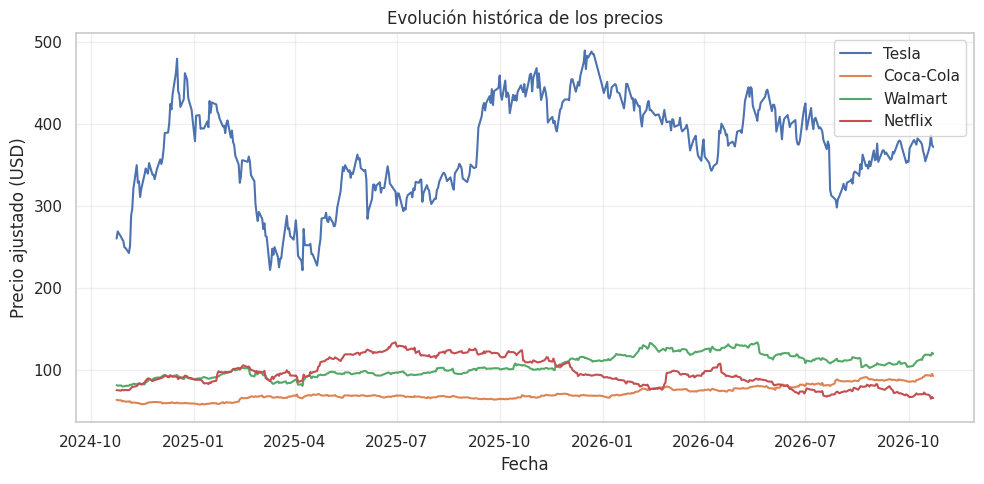


PASO 4. PRECIOS NORMALIZADOS


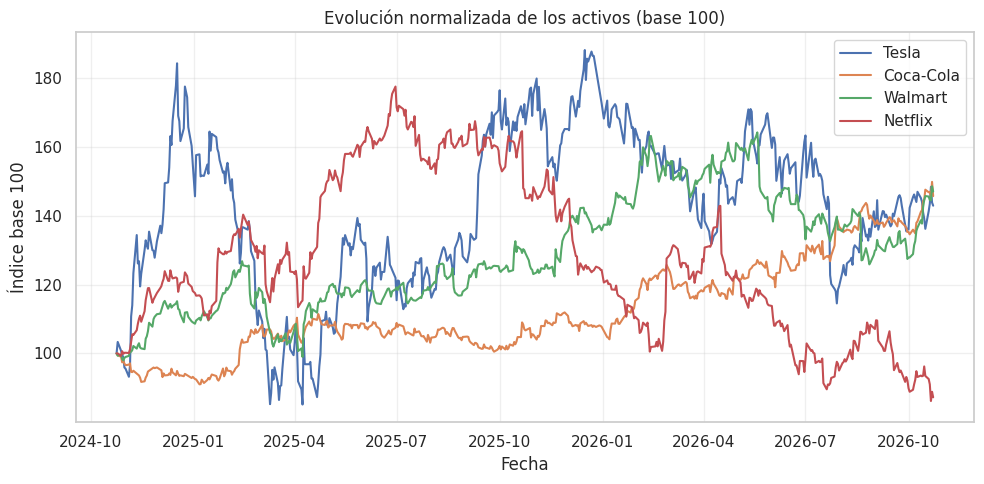


Índice inicial:
Ticker
TSLA    100.0
KO      100.0
WMT     100.0
NFLX    100.0
Name: 2024-10-24 00:00:00, dtype: float64

Índice final:
Ticker
TSLA    142.90
KO      145.67
WMT     147.01
NFLX     87.27
Name: 2026-10-23 00:00:00, dtype: float64

PASO 5. RENDIMIENTOS DIARIOS

Primeros rendimientos diarios:
Ticker          TSLA        KO       WMT      NFLX
Date                                              
2024-10-25  0.033438 -0.005646 -0.006382  0.000172
2024-10-28 -0.024815 -0.003736  0.002909 -0.007367
2024-10-29 -0.011390 -0.016649 -0.012689  0.013776
2024-10-30 -0.007591  0.005491 -0.003794 -0.007506
2024-10-31 -0.029897 -0.009254  0.006880  0.003038

Resumen estadístico:
Ticker      TSLA        KO       WMT      NFLX
count   500.0000  500.0000  500.0000  500.0000
mean      0.0014    0.0008    0.0009   -0.0000
std       0.0362    0.0115    0.0160    0.0217
min      -0.1543   -0.0444   -0.0915   -0.1007
25%      -0.0189   -0.0067   -0.0078   -0.0104
50%       0.0002    0.0002    0

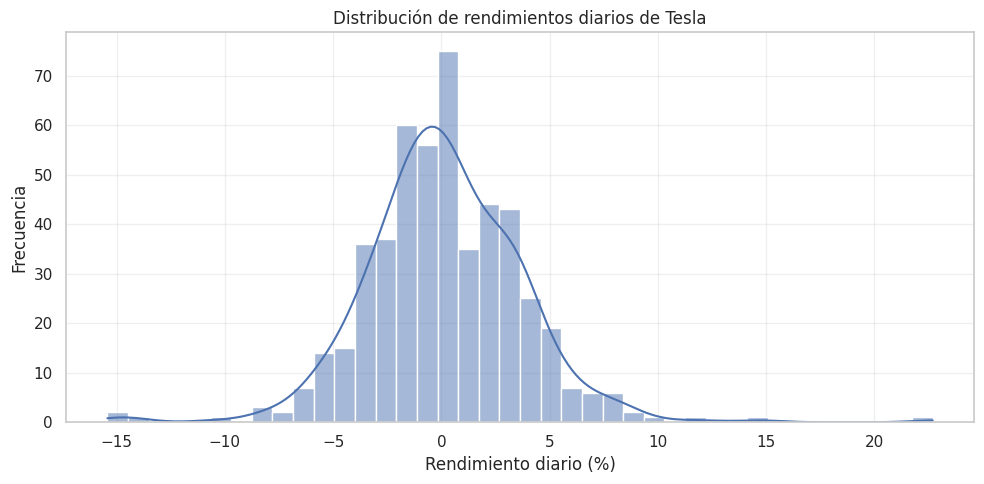


PASO 7. COMPARACIÓN DE RENDIMIENTOS


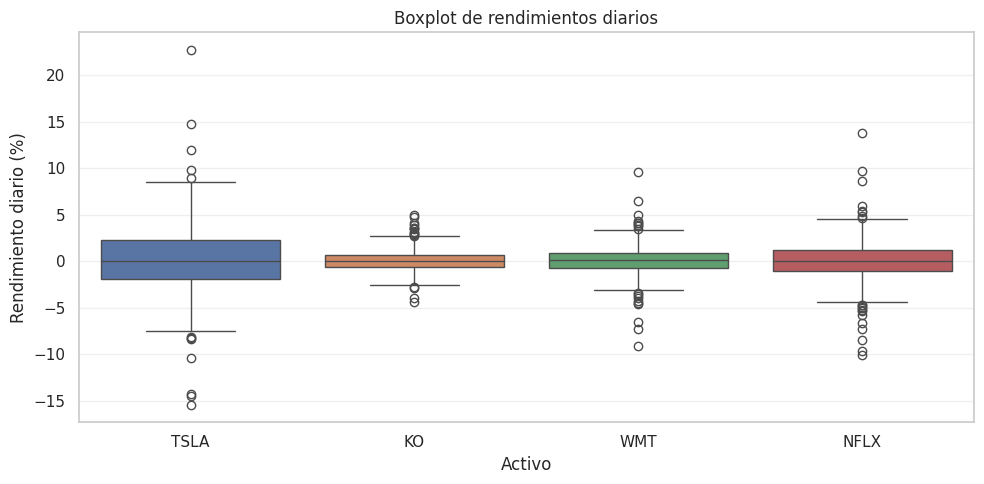


Volatilidad diaria (%):
Ticker
TSLA    3.6243
KO      1.1484
WMT     1.5966
NFLX    2.1702
dtype: float64

PASO 8. MATRIZ DE CORRELACIÓN


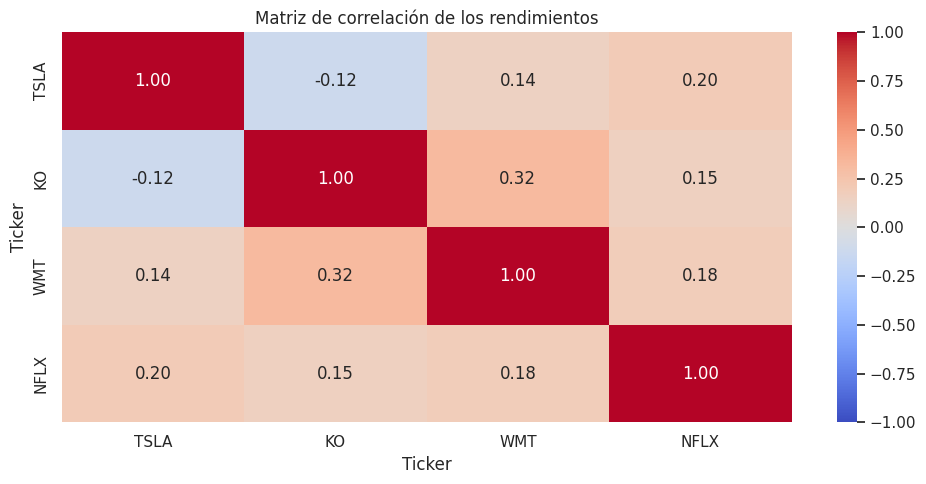


Valores de correlación:
Ticker   TSLA     KO    WMT   NFLX
Ticker                            
TSLA    1.000 -0.124  0.143  0.196
KO     -0.124  1.000  0.320  0.149
WMT     0.143  0.320  1.000  0.182
NFLX    0.196  0.149  0.182  1.000

PASO 9. RELACIÓN ENTRE TESLA Y NETFLIX


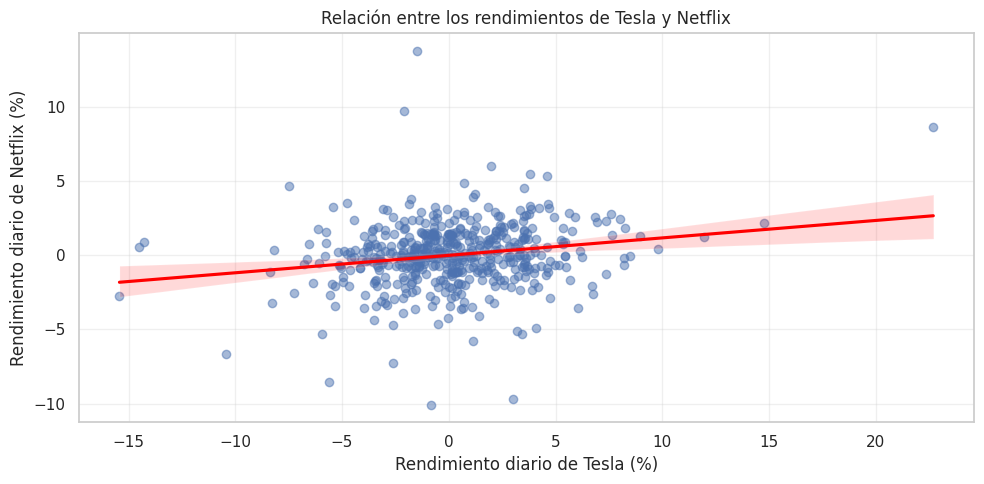

Correlación entre Tesla y Netflix: 0.196

PASO 10. CONCLUSIONES DEL EDA

HALLAZGO 1: EVOLUCIÓN NORMALIZADA
Gráfico: evolución de precios normalizados con base 100.
Observación: al finalizar el período, Walmart presenta el mayor cambio relativo ( 47.01 %), mientras que Netflix presenta el menor ( -12.73 %).
Interpretación: la normalización permite comparar el cambio relativo de los activos desde una misma base.

HALLAZGO 2: VARIABILIDAD DE LOS RENDIMIENTOS
Gráfico: boxplot de rendimientos diarios.
Observación: la mayor desviación estándar diaria corresponde a Tesla ( 3.624 %).
Interpretación: este activo mostró mayor variabilidad diaria en sus rendimientos durante el período analizado.

HALLAZGO 3: RELACIÓN ENTRE ACTIVOS
Gráfico: matriz de correlación.
Observación: la mayor correlación es entre Coca-Cola y Walmart con un valor de 0.32 . La menor correlación es entre Tesla y Coca-Cola con un valor de -0.124 .
Interpretación: las correlaciones muestran qué pares de activos han tenido movi

In [3]:

# MINI-PROYECTO: EDA COMPLETO

# Activos: Tesla, Coca-Cola, Walmart y Netflix

# PASO 1. IMPORTAR LIBRERIAS Y DESCARGAR DATOS

!pip install yfinance -q

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

# Configuración visual básica
sns.set_theme(style="whitegrid")

# Para que los gráficos aparezcan dentro del notebook
%matplotlib inline

activos = ["TSLA", "KO", "WMT", "NFLX"]

nombres = {
    "TSLA": "Tesla",
    "KO": "Coca-Cola",
    "WMT": "Walmart",
    "NFLX": "Netflix"
}

datos = yf.download(
    activos,        # Tickers
    period="2y",    # Datos de los 2 ultimos años
    interval="1d",  # Frecuencia de los datos 1 dia
    auto_adjust=True, # Reflejan los ajustes por eventos corporativos como
    # dividendos o desdoblamientos de acciones (splits)
    # evitando saltos artificiales en los gráficos y muestra
    # el el rendimiento real del activo
    progress=False, # Para que la ejecución del script sea más limpia visualmente
    multi_level_index=False # Evita que pandas cree un índice de múltiples niveles
     # (columnas agrupadas jerárquicamente) si estás descargando varios activos
)

# Extraer precios de cierre
if isinstance(datos.columns, pd.MultiIndex):
    precios = datos.xs("Close", axis=1, level=0)
else:
    precios = datos["Close"]

precios = precios.reindex(columns=activos)
precios = precios.sort_index()

print("=" * 60)
print("PASO 1. DESCARGA DE DATOS")
print("=" * 60)
print("Activos:", activos)
print(precios.head())

# PASO 2. CALIDAD DE LOS DATOS

print("\n" + "=" * 60)
print("PASO 2. CALIDAD DE LOS DATOS")
print("=" * 60)

print("\nDimensiones (filas, columnas):")
print(precios.shape)

print("\nTipos de datos:")
print(precios.dtypes)

print("\nValores faltantes por activo:")
print(precios.isnull().sum())

print("\nFecha inicial:", precios.index.min().date())
print("Fecha final:", precios.index.max().date())

print("\nInformación general:")
precios.info()

# Trabajamos con fechas que tienen datos para los cuatro activos
precios_limpios = precios.dropna()

print("\nDimensiones después de eliminar filas incompletas:")
print(precios_limpios.shape)

if precios_limpios.empty:
    raise ValueError(
        "No hay fechas comunes para los cuatro activos. "
        "Revisa la descarga de datos."
    )

# PASO 3. EVOLUCION DE LOS PRECIOS

print("\nPASO 3. EVOLUCIÓN DE PRECIOS")

plt.figure(figsize=(10, 5))

for activo in activos:
    plt.plot(
        precios.index,
        precios[activo],
        label=nombres[activo]
    )

plt.title("Evolución histórica de los precios")
plt.xlabel("Fecha")
plt.ylabel("Precio ajustado (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# PASO 4. NORMALIZACION CON BASE 100

print("\nPASO 4. PRECIOS NORMALIZADOS")

precios_normalizados = (
    precios_limpios.div(precios_limpios.iloc[0]) * 100
)

plt.figure(figsize=(10, 5))

for activo in activos:
    plt.plot(
        precios_normalizados.index,
        precios_normalizados[activo],
        label=nombres[activo]
    )

plt.title("Evolución normalizada de los activos (base 100)")
plt.xlabel("Fecha")
plt.ylabel("Índice base 100")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nÍndice inicial:")
print(precios_normalizados.iloc[0])

print("\nÍndice final:")
print(precios_normalizados.iloc[-1].round(2))

# PASO 5. RENDIMIENTOS DIARIOS

print("\nPASO 5. RENDIMIENTOS DIARIOS")

rendimientos = precios_limpios.pct_change().dropna()

print("\nPrimeros rendimientos diarios:")
print(rendimientos.head())

print("\nResumen estadístico:")
print(rendimientos.describe().round(4))

print("\nRendimientos promedio diarios (%):")
print((rendimientos.mean() * 100).round(4))

# PASO 6. HISTOGRAMA DE TESLA

print("\nPASO 6. DISTRIBUCIÓN DE LOS RENDIMIENTOS DE TESLA")

plt.figure(figsize=(10, 5))

sns.histplot(
    rendimientos["TSLA"].dropna() * 100,
    bins=40,
    kde=True
)

plt.title("Distribución de rendimientos diarios de Tesla")
plt.xlabel("Rendimiento diario (%)")
plt.ylabel("Frecuencia")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# PASO 7. BOXPLOT DE LOS RENDIMIENTOS

print("\nPASO 7. COMPARACIÓN DE RENDIMIENTOS")

plt.figure(figsize=(10, 5))

sns.boxplot(data=rendimientos[activos] * 100)

plt.title("Boxplot de rendimientos diarios")
plt.xlabel("Activo")
plt.ylabel("Rendimiento diario (%)")
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nVolatilidad diaria (%):")
volatilidad_diaria = rendimientos.std() * 100
print(volatilidad_diaria.round(4))

# PASO 8. MATRIZ DE CORRELACION

print("\nPASO 8. MATRIZ DE CORRELACIÓN")

correlacion = rendimientos.corr()

plt.figure(figsize=(10, 5))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Matriz de correlación de los rendimientos")
plt.tight_layout()
plt.show()

print("\nValores de correlación:")
print(correlacion.round(3))

# PASO 9. SCATTER PLOT: TESLA Y NETFLIX

print("\nPASO 9. RELACIÓN ENTRE TESLA Y NETFLIX")

plt.figure(figsize=(10, 5))

sns.regplot(
    x=rendimientos["TSLA"] * 100,
    y=rendimientos["NFLX"] * 100,
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Relación entre los rendimientos de Tesla y Netflix")
plt.xlabel("Rendimiento diario de Tesla (%)")
plt.ylabel("Rendimiento diario de Netflix (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

correlacion_tesla_netflix = correlacion.loc["TSLA", "NFLX"]

print(
    "Correlación entre Tesla y Netflix:",
    round(correlacion_tesla_netflix, 3)
)

# PASO 10. TRES HALLAZGOS BASADOS EN LOS RESULTADOS

print("\n" + "=" * 60)
print("PASO 10. CONCLUSIONES DEL EDA")
print("=" * 60)

# Hallazgo 1: crecimiento relativo
crecimiento = precios_normalizados.iloc[-1] - 100
activo_mayor_crecimiento = crecimiento.idxmax()
activo_menor_crecimiento = crecimiento.idxmin()

print("\nHALLAZGO 1: EVOLUCIÓN NORMALIZADA")
print("Gráfico: evolución de precios normalizados con base 100.")
print(
    "Observación: al finalizar el período,",
    nombres[activo_mayor_crecimiento],
    "presenta el mayor cambio relativo (",
    round(crecimiento[activo_mayor_crecimiento], 2),
    "%), mientras que",
    nombres[activo_menor_crecimiento],
    "presenta el menor (",
    round(crecimiento[activo_menor_crecimiento], 2),
    "%)."
)
print(
    "Interpretación: la normalización permite comparar "
    "el cambio relativo de los activos desde una misma base."
)

# Hallazgo 2: volatilidad
activo_mayor_volatilidad = volatilidad_diaria.idxmax()

print("\nHALLAZGO 2: VARIABILIDAD DE LOS RENDIMIENTOS")
print("Gráfico: boxplot de rendimientos diarios.")
print(
    "Observación: la mayor desviación estándar diaria corresponde a",
    nombres[activo_mayor_volatilidad],
    "(",
    round(volatilidad_diaria[activo_mayor_volatilidad], 3),
    "%)."
)
print(
    "Interpretación: este activo mostró mayor variabilidad diaria "
    "en sus rendimientos durante el período analizado."
)

# Hallazgo 3: relación entre activos
pares = list(combinations(activos, 2))
correlaciones_pares = {
    (a, b): correlacion.loc[a, b] for a, b in pares
}

par_mayor = max(correlaciones_pares, key=correlaciones_pares.get)
par_menor = min(correlaciones_pares, key=correlaciones_pares.get)

a, b = par_mayor
c, d = par_menor

print("\nHALLAZGO 3: RELACIÓN ENTRE ACTIVOS")
print("Gráfico: matriz de correlación.")
print(
    "Observación: la mayor correlación es entre",
    nombres[a], "y", nombres[b],
    "con un valor de", round(correlaciones_pares[par_mayor], 3),
    ". La menor correlación es entre",
    nombres[c], "y", nombres[d],
    "con un valor de", round(correlaciones_pares[par_menor], 3), "."
)
print(
    "Interpretación: las correlaciones muestran qué pares de activos "
    "han tenido movimientos más similares o menos similares. "
    "La correlación no implica causalidad."
)

print("\nEDA COMPLETADO.")


# Identificar rendimientos extremos: variaciones mayores al 5 %
# en valor absoluto

extremos = rendimientos[
    rendimientos.abs().ge(0.05).sum(axis=1) >= 2
]

print("Días con movimientos extremos en dos o más activos:")
print(extremos * 100)







